# Soul mates with Bayes, on the POLYMOD survey

POLYMOD asked 7290 people in 8 European countries in 2005 and 2006 to write down everyone they met on one day (Mossong et al. 2008, Zenodo record 3874557, licence CC BY-NC 4.0). For each contact they said how often they usually meet that person. A contact marked "first time" is a new person. Run `uv run python scripts/download_polymod.py` once before this notebook.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from soulmates.model import age_band, build_model, p_find
from soulmates.polymod import load_polymod

df = load_polymod("../data/raw")
df.head()

no part_age: 65 of 7290 rows (0.9%)
no dayofweek: 136 of 7290 rows (1.9%)
no frequency_multi: 1407 of 97904 rows (1.4%)


,age,new_contacts,weekend
0,8,3,False
1,6,0,False
2,0,2,False
3,1,0,False
4,2,0,False


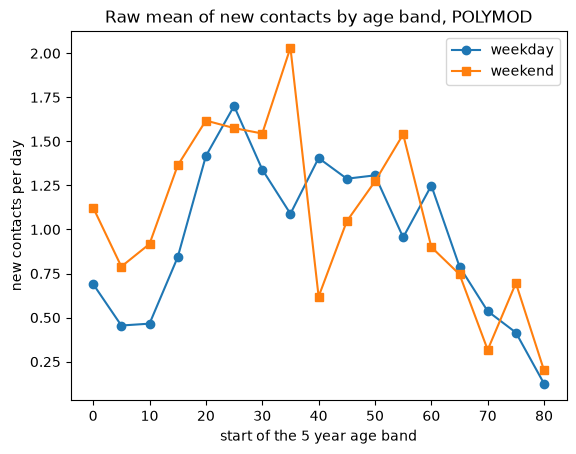

In [2]:
raw = df.groupby([age_band(df["age"]), "weekend"])["new_contacts"].mean().unstack()
fig, ax = plt.subplots()
ax.plot(raw.index * 5, raw[False], "o-", label="weekday")
ax.plot(raw.index * 5, raw[True], "s-", label="weekend")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per day", title="Raw mean of new contacts by age band, POLYMOD")
ax.legend();

## Fit

The model is the one from the simulated notebook, plus a weekend term `beta_weekend`. A weekend day has exp(beta_weekend) times the new contacts of a weekday.

In [3]:
model = build_model(df)
with model:
    idata = pm.sample(random_seed=2)
az.summary(idata, var_names=["mu_pop", "sigma_band", "alpha", "beta_weekend", "lifetime_new"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, beta_weekend, alpha, p_eye, p_recog]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 117 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_pop,-0.119,0.123,-0.31,0.071,665,840,1.00,0.0048,0.0031
sigma_band,0.459,0.107,0.32,0.65,770,1317,1.01,0.0038,0.0028
alpha,0.2331,0.0073,0.22,0.25,5071,2890,1.00,0.0001,0.00013
beta_weekend,0.218,0.066,0.11,0.32,5726,2811,1.00,0.00087,0.0012
lifetime_new,2.07e+04,7.89e+02,19000,22000,4488,3474,1.00,12,10


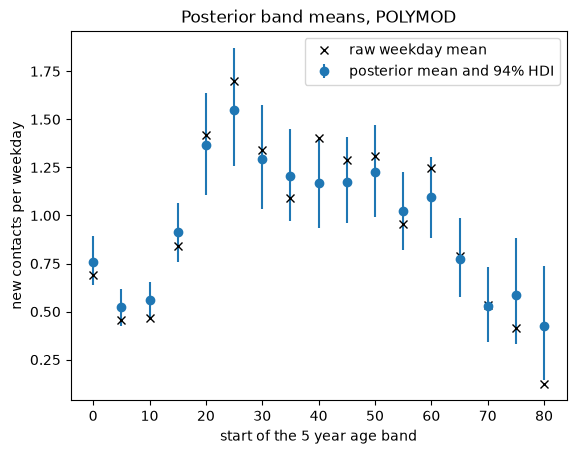

In [4]:
hdi = az.hdi(idata, var_names=["band_mean"], prob=0.94)["band_mean"].values
mean = idata.posterior["band_mean"].mean(("chain", "draw")).values
ages = np.arange(17) * 5
fig, ax = plt.subplots()
ax.errorbar(ages, mean, yerr=[mean - hdi[:, 0], hdi[:, 1] - mean], fmt="o", label="posterior mean and 94% HDI")
ax.plot(raw.index * 5, raw[False], "kx", label="raw weekday mean")
ax.set(xlabel="start of the 5 year age band", ylabel="new contacts per weekday", title="Posterior band means, POLYMOD")
ax.legend();

weekend multiplier 1.25, 94% interval 1.10 to 1.41
lifetime new contacts 20688, 94% interval 19264 to 22210


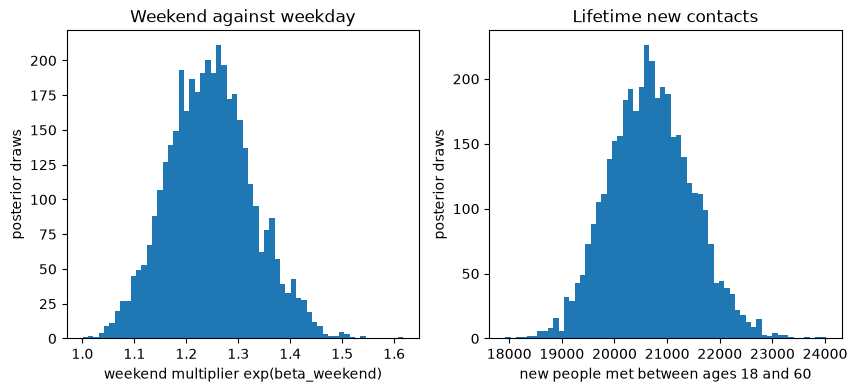

In [5]:
multiplier = np.exp(idata.posterior["beta_weekend"].values.ravel())
lifetime = idata.posterior["lifetime_new"].values.ravel()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(multiplier, bins=60)
ax1.set(xlabel="weekend multiplier exp(beta_weekend)", ylabel="posterior draws", title="Weekend against weekday")
ax2.hist(lifetime, bins=60)
ax2.set(xlabel="new people met between ages 18 and 60", ylabel="posterior draws", title="Lifetime new contacts")
print(f"weekend multiplier {multiplier.mean():.2f}, 94% interval {np.percentile(multiplier, 3):.2f} to {np.percentile(multiplier, 97):.2f}")
print(f"lifetime new contacts {lifetime.mean():.0f}, 94% interval {np.percentile(lifetime, 3):.0f} to {np.percentile(lifetime, 97):.0f}")

## The chance of finding your soul mate

P_find = 1 − (1 − p_recog / M) ^ eye_contacts. M is still a placeholder until the UN World Population Prospects cohort sizes are in, and p_eye and p_recog are still guesses.

In [6]:
POOL_SIZE = 1e8  # PLACEHOLDER until the UN WPP cohort sizes arrive
pf = p_find(idata, POOL_SIZE).values.ravel()
print(f"P_find mean {pf.mean():.2e}, 94% interval {np.percentile(pf, 3):.2e} to {np.percentile(pf, 97):.2e}")

P_find mean 5.12e-05, 94% interval 5.73e-06 to 1.29e-04


## Known limits

1. Some participants may have reported extra contacts only as a total, without a frequency. If so, those contacts are missing here and the count of new contacts is too low. This has not been checked. The columns would be in `2008_Mossong_POLYMOD_participant_extra.csv`, which is not downloaded.
2. The recovery test runs at alpha = 2, while this data sits near alpha = 0.23. The model is not tested at that level of spread.
3. All 8 countries are pooled into one sample.